<a href="https://colab.research.google.com/github/ArifahZhafirah/PEMBELAJARAN-MESIN/blob/main/JS08/TUGAS-LAB01/PEMMESTUGAS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Tugas Lab 1: Agglomerative Clustering (Data Nasabah Kartu Kredit)

#Tugas Lab 1 - Agglomerative Clustering pada Data Nasabah Kartu Kredit

Import Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Load Dataset

In [2]:
# Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Inspect info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


Slicing Fitur

In [3]:
# Slicing - Select all usable variables (skip Sl_No and Customer Key)
# Cek urutan kolom di hasil df.info() lalu sesuaikan indeksnya
# Dua kolom pertama harus Avg_Credit_Limit dan Total_credit_card
X = df.iloc[:, [2, 3, 4, 5, 6]].values

Visualisasi Dendrogram

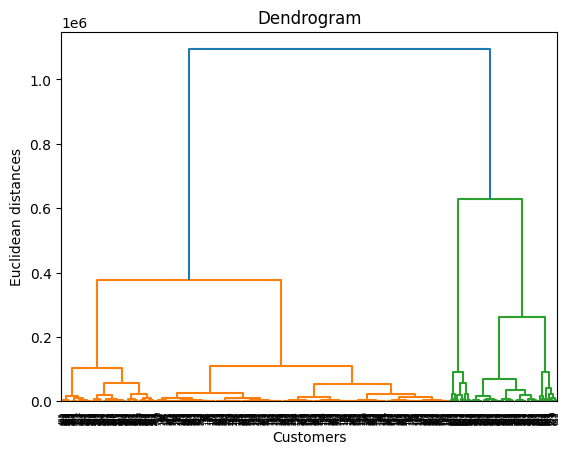

In [4]:
# Build dendogram
import scipy.cluster.hierarchy as sch

# Build dendogram using ward distance
dendrogram = sch.dendrogram(sch.linkage(X, method = 'ward'))

# Plot
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

Membuat Model Agglomerative

In [5]:
# Build Cluster using Agglomerative Method
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 3, metric = 'euclidean', linkage = 'ward')  # ganti n_clusters sesuai dendrogram
y_hc = hc.fit_predict(X)

Visualisasi Cluster (scatter Avg_Credit_Limit vs Total_credit_card)

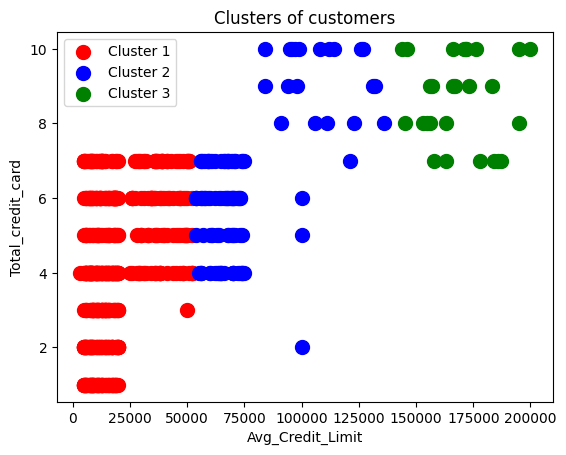

In [6]:
# Visualize The Result
plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s = 100, c = 'blue', label = 'Cluster 2')
plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s = 100, c = 'green', label = 'Cluster 3')
plt.title('Clusters of customers')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_credit_card')
plt.legend()
plt.show()

Evaluasi Hasil Cluster (Silhouette dan DBI)

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Evaluate the clustering using silhouette coefficient
silhouette_avg = silhouette_score(X, y_hc)
print(f'Silhouette Coefficient: {silhouette_avg}')

# Evaluate the clustering using Davies-Bouldin Index
dbi_score = davies_bouldin_score(X, y_hc)
print(f'Davies-Bouldin Index: {dbi_score}')

Silhouette Coefficient: 0.6811232268244817
Davies-Bouldin Index: 0.38800576073929305
